In [1]:
!pip install ultralytics roboflow opencv-python matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 44.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 113.7 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [2]:
import os
import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from ultralytics import YOLO
from roboflow import Roboflow

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [5]:
from roboflow import Roboflow
from getpass import getpass

# Enter your Roboflow API key
api_key = getpass("Enter your Roboflow API Key: ")

# Connect to Roboflow
rf = Roboflow(api_key=api_key)

# Select workspace
workspace = rf.workspace("gfo-fc1de")

# Select project
project = workspace.project("fire-and-smoke-detector-yykya")

# Select dataset version
version = project.version(14)

# Download dataset in YOLO format
dataset = version.download("yolov8")

# Display dataset location
print("Dataset downloaded successfully!")
print("Dataset location:", dataset.location)

Enter your Roboflow API Key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fire-and-smoke-detector-14 in yolov8:: 100%|██████████| 11204/11204 [00:01<00:00, 7107.69it/s]

Dataset downloaded successfully!
Dataset location: /content/fire-and-smoke-detector-14


In [6]:
dataset_path = Path(dataset.location)

print("Dataset location:", dataset_path)

print("\nDataset contents:")

for item in dataset_path.iterdir():
    print(item.name)

Dataset location: /content/fire-and-smoke-detector-14

Dataset contents:
README.dataset.txt
valid
test
README.roboflow.txt
data.yaml
train


train: Images used to train the model.



valid: Images used to evaluate the model during training.



test: Images reserved for final evaluation.



data.yaml: Contains dataset paths and class names.

In [7]:
data_yaml_path = dataset_path / "data.yaml"

with open(data_yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

print(data_config)

{'names': ['fire', 'smoke'], 'nc': 2, 'roboflow': {'license': 'CC BY 4.0', 'project': 'fire-and-smoke-detector-yykya', 'url': 'https://universe.roboflow.com/gfo-fc1de/fire-and-smoke-detector-yykya/dataset/14', 'version': 14, 'workspace': 'gfo-fc1de'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


In [8]:
# Load the YOLO nano pretrained model
model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [9]:
# Train the YOLO model
results = model.train(
    data=str(data_yaml_path),
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    name="fire_smoke_detection",
    project="runs/detect",
    plots=True
)

print("Training completed!")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire-and-smoke-detector-14/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fire_smoke_detection, nbs=64, nms=None, ops

KeyboardInterrupt: 

In [10]:
from pathlib import Path

results_path = Path("runs/detect/fire_smoke_detection")

print("Best model exists:",
      (results_path / "weights" / "best.pt").exists())

print("Last model exists:",
      (results_path / "weights" / "last.pt").exists())

Best model exists: False
Last model exists: False


In [11]:
import os

for root, dirs, files in os.walk("runs"):
    for file in files:
        if file in ["best.pt", "last.pt", "results.csv"]:
            print(os.path.join(root, file))

runs/detect/runs/detect/fire_smoke_detection/results.csv
runs/detect/runs/detect/fire_smoke_detection/weights/last.pt
runs/detect/runs/detect/fire_smoke_detection/weights/best.pt


In [12]:
from pathlib import Path

results_path = Path("runs/detect/runs/detect/fire_smoke_detection")

best_weights = results_path / "weights" / "best.pt"
last_weights = results_path / "weights" / "last.pt"

print("Best model exists:", best_weights.exists())
print("Last model exists:", last_weights.exists())

Best model exists: True
Last model exists: True


YOLO saves two important model weight files:
- best.pt: Contains the model weights from the epoch with the best validation fitness. It is usually preferred for final predictions.
- last.pt: Contains the model weights from the last completed training epoch. It is useful for resuming training.

In [13]:
# Load the best trained model
best_model = YOLO(
    str(results_path / "weights" / "best.pt")
)

print("Best model loaded successfully!")

Best model loaded successfully!


In [16]:
import pandas as pd
import matplotlib.pyplot as plt

csv_path = results_path / "results.csv"
df = pd.read_csv(csv_path)

print(df.columns.tolist())
print(df.tail())

['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
    epoch      time  train/box_loss  train/cls_loss  train/dfl_loss  \
15     16   979.143         1.82333         1.89845         1.75311   
16     17  1036.680         1.79835         1.85449         1.74136   
17     18  1096.050         1.78953         1.86975         1.75092   
18     19  1153.750         1.78297         1.83580         1.73617   
19     20  1213.730         1.77691         1.82521         1.73897   

    metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
15               0.56305            0.44036           0.46817   
16               0.55606            0.47732           0.48571   
17               0.57966            0.46637           0.48788   
18               0.56101            0.47281           0.48062   
19        

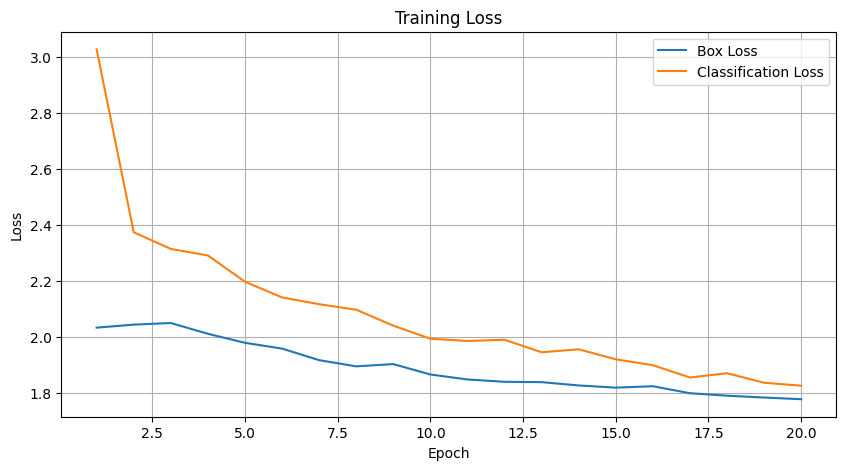

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(df["epoch"], df["train/box_loss"], label="Box Loss")
plt.plot(df["epoch"], df["train/cls_loss"], label="Classification Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid()
plt.show()

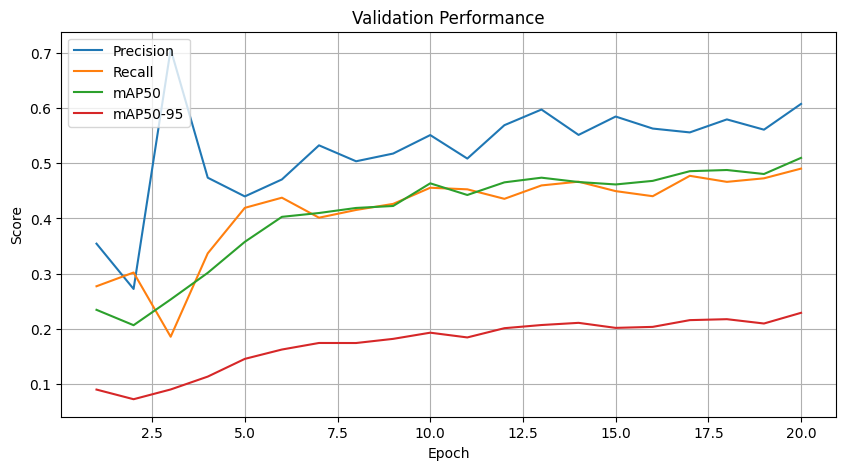

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(df["epoch"], df["metrics/precision(B)"], label="Precision")
plt.plot(df["epoch"], df["metrics/recall(B)"], label="Recall")
plt.plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Performance")
plt.legend()
plt.grid()
plt.show()

In [19]:
plt.savefig("training_performance.png")

<Figure size 640x480 with 0 Axes>

In [21]:
metrics = best_model.val(
    data=str(data_yaml_path),
    split="val",
    imgsz=640,
    plots=True
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1208.6±534.1 MB/s, size: 43.6 KB)
val: Scanning /content/fire-and-smoke-detector-14/valid/labels.cache... 1017 images, 105 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 1017/1017 193.9Mit/s 0.0s
val: /content/fire-and-smoke-detector-14/valid/images/WaterMistFireDemonstration3447_png.rf.8b898bfa25fa838fbdea67cf21cd9556.jpg: ignoring corrupt image/label: labels mix segment and detection rows
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 64/64 5.3it/s 12.1s
                   all       1016       1651      0.609       0.49       0.51      0.229
                  fire        835       1030      0.639      0.638      0.649      0.304
                 smoke        420        621      0.579      0.343      0.371      0.154
Sp

In [22]:
from IPython.display import Image, display

confusion_matrix_path = results_path / "confusion_matrix.png"

if confusion_matrix_path.exists():
    display(Image(filename=str(confusion_matrix_path)))
else:
    print("Check the validation output folder for the confusion matrix.")

Check the validation output folder for the confusion matrix.


In [23]:
# Evaluate the best model on the validation dataset
metrics = best_model.val(
    data=str(data_yaml_path),
    split="val",
    imgsz=640
)

# Display evaluation metrics
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1878.9±771.1 MB/s, size: 41.7 KB)
val: Scanning /content/fire-and-smoke-detector-14/valid/labels.cache... 1017 images, 105 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 1017/1017 193.9Mit/s 0.0s
val: /content/fire-and-smoke-detector-14/valid/images/WaterMistFireDemonstration3447_png.rf.8b898bfa25fa838fbdea67cf21cd9556.jpg: ignoring corrupt image/label: labels mix segment and detection rows
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 64/64 5.7it/s 11.2s
                   all       1016       1651      0.609       0.49       0.51      0.229
                  fire        835       1030      0.639      0.638      0.649      0.304
                 smoke        420        621      0.579      0.343      0.371      0.154
Sp

In [24]:
from google.colab import files

# Upload a fire or smoke video
uploaded = files.upload()

# Get the uploaded video filename
video_path = list(uploaded.keys())[0]

print("Uploaded video:", video_path)

Saving 10802656-hd_3840_2160_24fps.mp4 to 10802656-hd_3840_2160_24fps (1).mp4
Uploaded video: 10802656-hd_3840_2160_24fps (1).mp4


In [25]:
# Open the uploaded video
cap = cv2.VideoCapture(video_path)

# Check if the video opened successfully
if not cap.isOpened():
    print("Error: Cannot open video")
else:
    print("Video opened successfully!")

    # Get video properties
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    print("Width:", width)
    print("Height:", height)
    print("FPS:", fps)

cap.release()

Video opened successfully!
Width: 3840
Height: 2160
FPS: 24.0


In [26]:
# Run prediction on the uploaded video
prediction_results = best_model.predict(
    source=video_path,
    conf=0.25,
    imgsz=640,
    save=True,
    project="runs/detect",
    name="fire_smoke_video",
    exist_ok=True
)

print("Video prediction completed!")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/173) /content/10802656-hd_3840_2160_24fps (1).mp4: 384x640 (no detections), 11.0ms
video 1/1 (frame 2/173) /content/10802656-hd_3840_2160_24fps (1).mp4: 384x640 (no detections), 12.3ms
video 1/1 (frame 3/173) /content/10802656-hd_3840_2160_24fps (1).mp4: 384x640 (no detections), 16.0ms
video 1/1 (frame 4/173) /content/10802656-hd_3840_2160_24fps (1).mp4: 384x640 (no detections), 13.2ms
video 1/1 (frame 5/173) /content/10802656-hd_3840_2

In [27]:
from IPython.display import Video, display

# Locate the saved prediction video
output_folder = Path("runs/detect/fire_smoke_video")

output_videos = list(output_folder.glob("*.avi")) + \
                list(output_folder.glob("*.mp4")) + \
                list(output_folder.glob("*.mov"))

if output_videos:

    output_video = output_videos[0]

    print("Output video:", output_video)

    display(Video(
        filename=str(output_video),
        embed=True
    ))

else:
    print("No output video found!")

No output video found!


In [30]:
from pathlib import Path

video_files = []

for ext in ["*.avi", "*.mp4", "*.mov", "*.mkv", "*.webm"]:
    video_files.extend(Path("runs").rglob(ext))

print("Videos found:")

for video in video_files:
    print(video)

Videos found:
runs/detect/runs/detect/fire_smoke_video/10802656-hd_3840_2160_24fps (1).avi


In [28]:
from google.colab import files

best_weights = results_path / "weights" / "best.pt"

files.download(str(best_weights))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
last_weights = results_path / "weights" / "last.pt"

files.download(str(last_weights))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
files.download(str(output_video))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>